In [1]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
import pandas as pd
import numpy as np
%matplotlib inline

In [7]:
X,y=make_blobs(n_samples=1000,centers=3,n_features=2, random_state = 16)

In [8]:
X

array([[-7.08894274,  0.46051653],
       [-5.10117701, -1.49022022],
       [-3.44072758, -4.89973901],
       ...,
       [-4.69132109, -0.13358442],
       [-2.8732577 , -5.09977508],
       [-6.93900598, -2.02337535]], shape=(1000, 2))

In [9]:
y

array([0, 0, 2, 1, 1, 0, 0, 1, 2, 2, 0, 0, 1, 2, 2, 0, 0, 1, 2, 1, 2, 2,
       1, 0, 0, 1, 1, 1, 2, 0, 1, 2, 1, 1, 1, 1, 0, 1, 1, 0, 0, 2, 2, 1,
       2, 2, 0, 2, 2, 1, 1, 2, 1, 2, 0, 1, 1, 0, 1, 0, 2, 1, 1, 0, 0, 0,
       0, 1, 0, 2, 2, 0, 2, 1, 0, 1, 2, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1,
       2, 0, 0, 1, 2, 1, 0, 0, 0, 2, 1, 2, 2, 0, 2, 1, 2, 1, 2, 2, 2, 0,
       1, 2, 0, 0, 0, 0, 0, 2, 0, 0, 0, 2, 2, 0, 1, 0, 0, 0, 1, 1, 1, 1,
       2, 2, 1, 1, 1, 0, 1, 2, 0, 2, 1, 2, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1,
       0, 1, 0, 2, 1, 2, 1, 1, 2, 1, 1, 2, 2, 0, 1, 2, 1, 0, 2, 1, 1, 2,
       0, 0, 1, 1, 0, 2, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 2, 2, 1, 0,
       0, 2, 1, 0, 2, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 0, 1, 1, 1, 2, 2, 2,
       2, 0, 2, 0, 0, 1, 0, 2, 0, 0, 1, 1, 1, 0, 2, 2, 2, 0, 2, 2, 2, 0,
       1, 1, 1, 0, 2, 1, 2, 0, 2, 1, 0, 1, 2, 2, 0, 2, 0, 1, 1, 1, 1, 1,
       0, 1, 1, 2, 1, 1, 1, 2, 1, 2, 1, 0, 2, 0, 2, 2, 2, 0, 1, 1, 2, 0,
       2, 1, 0, 1, 1, 1, 0, 1, 1, 0, 2, 2, 0, 0, 0,

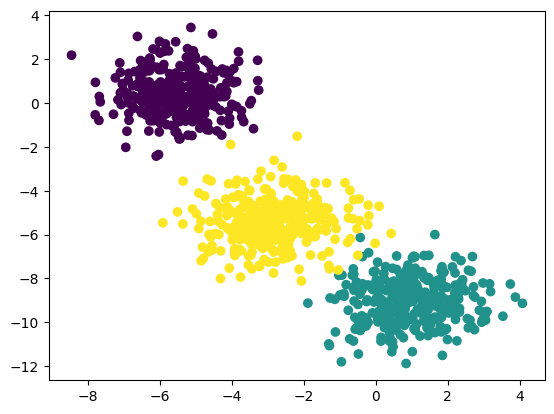

In [10]:
plt.scatter(X[:,0],X[:,1],c=y)

In [11]:
## standardization--feature scaling technique
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()

In [13]:
from sklearn.model_selection import train_test_split

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=42)

In [15]:
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [16]:
from sklearn.cluster import KMeans

In [17]:
## Elbow method To select K Value
wcss=[]
for k in range(1,11):
    kmeans=KMeans(n_clusters=k,init="k-means++") #random initialize
    kmeans.fit(X_train_scaled)
    wcss.append(kmeans.inertia_)

In [19]:
print(wcss)

[1340.0, 396.4359271411374, 126.82400035278542, 112.28040167870721, 89.50553146808687, 72.26086046374759, 66.0006768598607, 60.37669207258387, 55.67484093441872, 50.12824754495848]


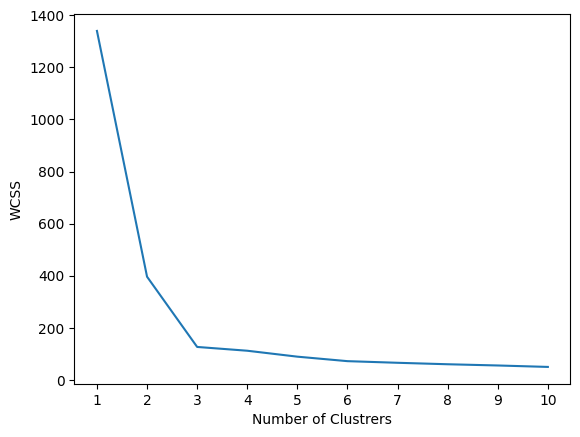

In [20]:
## plot elbow curve
plt.plot(range(1,11),wcss)
plt.xticks(range(1,11))
plt.xlabel("Number of Clustrers")
plt.ylabel("WCSS")
plt.show()

In [21]:
model=KMeans(n_clusters=3,init="k-means++")
KMeans = model.fit(X_train_scaled)

In [22]:
y_pred=KMeans.predict(X_test_scaled)

In [23]:
y_pred

array([2, 2, 2, 2, 0, 1, 2, 1, 1, 1, 2, 2, 2, 2, 1, 2, 2, 1, 0, 1, 0, 1,
       2, 0, 2, 2, 0, 2, 1, 0, 0, 2, 1, 2, 1, 0, 2, 2, 0, 0, 2, 0, 2, 0,
       0, 0, 1, 0, 0, 2, 1, 1, 1, 2, 0, 1, 2, 0, 0, 2, 2, 0, 2, 2, 1, 0,
       2, 1, 2, 1, 2, 1, 1, 1, 0, 1, 1, 0, 0, 2, 1, 0, 0, 1, 2, 1, 2, 2,
       1, 1, 0, 1, 0, 2, 2, 0, 2, 2, 0, 0, 2, 1, 1, 0, 0, 0, 0, 2, 1, 2,
       1, 1, 1, 0, 1, 2, 1, 0, 2, 1, 2, 1, 0, 1, 0, 0, 1, 2, 0, 0, 2, 0,
       1, 2, 1, 1, 0, 1, 1, 2, 2, 1, 0, 0, 2, 0, 2, 1, 0, 0, 0, 1, 2, 0,
       0, 1, 2, 0, 2, 0, 2, 0, 2, 0, 2, 1, 0, 0, 0, 2, 1, 0, 1, 2, 2, 2,
       2, 1, 2, 1, 0, 1, 2, 2, 2, 0, 2, 0, 2, 0, 2, 1, 1, 2, 0, 0, 2, 1,
       0, 0, 0, 0, 0, 2, 0, 2, 2, 0, 0, 2, 0, 2, 0, 0, 2, 1, 2, 0, 0, 0,
       0, 0, 0, 1, 1, 2, 0, 0, 1, 1, 1, 2, 1, 2, 1, 2, 1, 0, 0, 0, 1, 1,
       2, 0, 0, 0, 2, 0, 1, 2, 0, 2, 2, 0, 1, 2, 2, 2, 2, 0, 2, 0, 2, 1,
       2, 0, 0, 1, 2, 1, 1, 0, 1, 2, 1, 2, 1, 1, 0, 1, 2, 0, 2, 1, 2, 1,
       1, 1, 2, 1, 1, 2, 2, 2, 0, 0, 2, 1, 1, 1, 1,

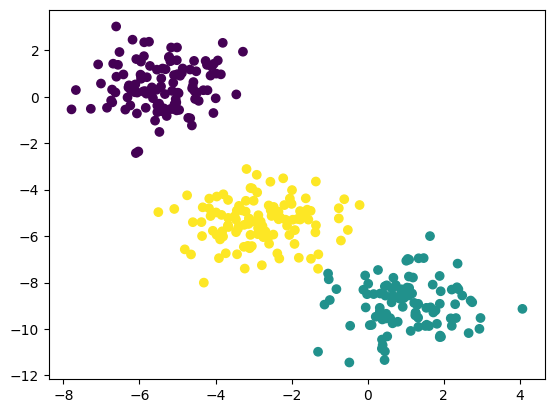

In [24]:
plt.scatter(X_test[:,0],X_test[:,1],c=y_pred)